# Datos históricos de Colombia por API — 15 ejemplos en Python

Social, económico y ambiental a nivel municipio, departamento y país.
Los ejemplos usan el Meta / Villavicencio como caso; cambia los filtros por tu territorio.

**Llave de cruce:** código DIVIPOLA (5 dígitos municipio, 2 departamento), siempre como texto con `zfill`.

In [1]:
# Instalación (solo la primera vez)
%pip install -q requests pandas wbgapi matplotlib
# Opcional para el ejemplo 15: %pip install -q earthengine-api

## 0. Función base para datos.gov.co (API Socrata / SoQL)

Pagina automáticamente y acepta `select`, `where`, `group` y `order` en SoQL.
Sin token funciona, pero con un *app token* gratuito (perfil en datos.gov.co → Developer Settings) evitas límites.

In [2]:
import os, time, requests, pandas as pd

BASE = "https://www.datos.gov.co/resource/{}.json"
TOKEN = os.getenv("SOCRATA_APP_TOKEN")          # opcional: os.environ["SOCRATA_APP_TOKEN"] = "..."
HEADERS = {"X-App-Token": TOKEN} if TOKEN else {}

def socrata(dataset_id, select=None, where=None, group=None, order=None,
            limit=50000, max_rows=None):
    """Descarga un dataset de datos.gov.co con paginación. Devuelve un DataFrame."""
    params = {"$limit": limit}
    if select: params["$select"] = select
    if where:  params["$where"]  = where
    if group:  params["$group"]  = group
    params["$order"] = order or (group if group else ":id")   # orden estable para paginar
    frames, offset = [], 0
    while True:
        params["$offset"] = offset
        r = requests.get(BASE.format(dataset_id), params=params, headers=HEADERS, timeout=120)
        r.raise_for_status()
        batch = r.json()
        if not batch:
            break
        frames.append(pd.DataFrame(batch))
        offset += len(batch)
        if len(batch) < limit or (max_rows and offset >= max_rows):
            break
        time.sleep(0.3)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

## 1. Buscar datasets en el catálogo de datos.gov.co

Así encuentras el `id` (formato `xxxx-xxxx`) de cualquier tema antes de descargarlo.

In [3]:
def buscar_datasets(texto, n=20):
    url = "https://api.us.socrata.com/api/catalog/v1"
    p = {"domains": "www.datos.gov.co", "search_context": "www.datos.gov.co",
         "q": texto, "limit": n, "only": "datasets"}
    res = requests.get(url, params=p, timeout=60).json()["results"]
    return pd.DataFrame([{
        "id": x["resource"]["id"],
        "nombre": x["resource"]["name"],
        "entidad": x["resource"].get("attribution"),
        "actualizado": x["resource"].get("data_updated_at"),
    } for x in res])

buscar_datasets("homicidios municipio")

,id,nombre,entidad,actualizado
0,m8fd-ahd9,HOMICIDIO,"Ministerio de Defensa Nacional - MinDefensa, B...",2026-09-16T20:52:06.000Z
1,ha6j-pa2r,Homicidios accidente de tránsito Policía Nacional,Dirección General de la Policía Nacional - DIP...,2026-09-01T20:24:46.000Z
2,8rme-4s7n,Guadalajara de Buga : Homicidios por Accidente...,"Alcaldía de Guadalajara de Buga, Valle del Cauca",2023-11-24T17:21:22.000Z
3,hk7a-5ix3,Homicidios en el municipio de Neiva,"Alcaldía de Neiva, Huila",2023-08-14T13:35:30.000Z
4,u8eq-92tb,MASACRES,"Ministerio de Defensa Nacional - MinDefensa, B...",2026-09-16T20:57:12.000Z
5,mg8y-amuh,Accidentes de transito Palmira 2020,"Alcaldía de Palmira, Valle del Cauca",2021-10-28T15:56:56.000Z
6,8rpn-wpty,AFECTACIÓN DE MIEMBROS DE LA FUERZA PÚBLICA,"Ministerio de Defensa Nacional - MinDefensa, B...",2026-09-16T19:40:45.000Z
7,uav5-b85g,HOMICIDIO EN ACCIDENTE DE TRÁNSITO,"Ministerio de Defensa Nacional - MinDefensa, B...",2026-08-18T15:58:30.000Z
8,24zx-8mzy,HOMICIDIOS 2012-2022 CORTE MARZO,"Alcaldía de Neiva, Huila",2022-05-27T02:24:03.000Z
9,ruiv-deeb,Siniestros viales Palmira 2020,"Alcaldía de Palmira, Valle del Cauca",2021-10-28T21:01:36.000Z


## 2. DIVIPOLA — códigos de departamentos y municipios (DANE) · `gdxc-w37w`

In [4]:
divipola = socrata("gdxc-w37w")
divipola["cod_mpio"] = divipola["cod_mpio"].astype(str).str.zfill(5)
divipola["cod_dpto"] = divipola["cod_dpto"].astype(str).str.zfill(2)
print(divipola.shape)
divipola[divipola["dpto"].str.upper() == "META"].head()

(1122, 7)


,cod_dpto,dpto,cod_mpio,nom_mpio,tipo_municipio,longitud,latitud
687,50,META,50001,VILLAVICENCIO,Municipio,"-73,622601","4,126369"
688,50,META,50006,ACACÍAS,Municipio,"-73,766034","3,990413"
689,50,META,50110,BARRANCA DE UPÍA,Municipio,"-72,961083","4,566225"
690,50,META,50124,CABUYARO,Municipio,"-72,791768","4,286705"
691,50,META,50150,CASTILLA LA NUEVA,Municipio,"-73,687302","3,830005"


## 3. Producción agrícola municipal (EVA) — serie 2007–2025

Dos tablas: MinAgricultura 2007–2018 (`2pnw-mmge`) y UPRA 2019–2025 (`uejq-wxrr`). Se armonizan y se unen.

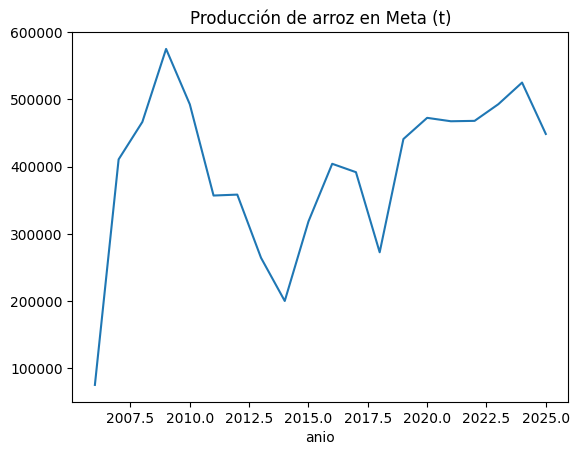

In [5]:
dep, cultivo = "META", "ARROZ"

eva_a = socrata("2pnw-mmge",
    where=f"upper(departamento)='{dep}' AND upper(cultivo) like '%{cultivo}%'")
eva_b = socrata("uejq-wxrr",
    where=f"upper(departamento)='{dep}' AND upper(cultivo) like '%{cultivo}%'")

eva_a = eva_a.rename(columns={"c_d_mun": "cod_mpio", "a_o": "anio", "rea_sembrada_ha": "area_sembrada",
                              "rea_cosechada_ha": "area_cosechada", "producci_n_t": "produccion_t"})
eva_b = eva_b.rename(columns={"c_digo_dane_municipio": "cod_mpio", "a_o": "anio", "rea_sembrada": "area_sembrada",
                              "rea_cosechada": "area_cosechada", "producci_n": "produccion_t"})
cols = ["cod_mpio", "municipio", "cultivo", "anio", "periodo", "area_sembrada", "area_cosechada", "produccion_t"]
eva = pd.concat([eva_a[cols], eva_b[cols]], ignore_index=True)
eva["cod_mpio"] = eva["cod_mpio"].astype(str).str.zfill(5)
eva["anio"] = pd.to_numeric(eva["anio"], errors="coerce")
for c in ["area_sembrada", "area_cosechada", "produccion_t"]:
    eva[c] = pd.to_numeric(eva[c], errors="coerce")

eva_anual = eva.groupby(["cod_mpio", "municipio", "anio"], as_index=False)["produccion_t"].sum()
eva.groupby("anio")["produccion_t"].sum().plot(title=f"Producción de {cultivo.lower()} en {dep.title()} (t)");

## 4. Saber 11 (ICFES) — puntaje promedio por municipio y periodo · `kgxf-xxbe`

La agregación se hace en el servidor (`$group`), así no descargas millones de registros.

In [6]:
saber = socrata("kgxf-xxbe",
    select=("cole_cod_mcpio_ubicacion, cole_mcpio_ubicacion, periodo, "
            "avg(punt_global::number) as prom_global, count(*) as estudiantes"),
    where="upper(cole_depto_ubicacion)='META'",
    group="cole_cod_mcpio_ubicacion, cole_mcpio_ubicacion, periodo")

saber["cod_mpio"] = saber["cole_cod_mcpio_ubicacion"].astype(str).str.zfill(5)
saber["anio"] = saber["periodo"].astype(str).str[:4].astype(int)
saber["prom_global"] = pd.to_numeric(saber["prom_global"])
saber["estudiantes"] = pd.to_numeric(saber["estudiantes"])
saber.sort_values(["cod_mpio", "periodo"]).head()

KeyboardInterrupt: 

## 5. Indicadores de educación por municipio (MinEducación) · `nudc-7mev`

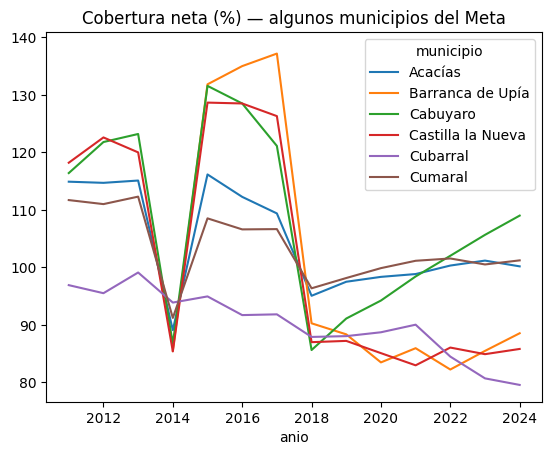

In [7]:
edu = socrata("nudc-7mev",
    select="a_o, c_digo_municipio, municipio, cobertura_neta, deserci_n, aprobaci_n, repitencia",
    where="upper(departamento)='META'")
edu = edu.rename(columns={"a_o": "anio", "c_digo_municipio": "cod_mpio", "deserci_n": "desercion",
                          "aprobaci_n": "aprobacion"})
edu["cod_mpio"] = edu["cod_mpio"].astype(str).str.zfill(5)
edu["anio"] = pd.to_numeric(edu["anio"])
for c in ["cobertura_neta", "desercion", "aprobacion", "repitencia"]:
    edu[c] = pd.to_numeric(edu[c], errors="coerce")
edu.pivot_table(index="anio", columns="municipio", values="cobertura_neta").iloc[:, :6].plot(
    title="Cobertura neta (%) — algunos municipios del Meta");

## 6. Contratación pública SECOP II — número y valor de contratos por año · `jbjy-vk9h`

In [8]:
secop = socrata("jbjy-vk9h",
    select=("date_extract_y(fecha_de_firma) as anio, count(*) as contratos, "
            "sum(valor_del_contrato) as valor_total"),
    where="upper(departamento)='META' AND fecha_de_firma >= '2018-01-01T00:00:00'",
    group="date_extract_y(fecha_de_firma)",
    order="date_extract_y(fecha_de_firma)")
secop = secop.astype({"anio": int, "contratos": int, "valor_total": float})
secop["valor_billones"] = secop["valor_total"] / 1e12
secop

,anio,contratos,valor_total,valor_billones
0,2018,1378,5.830000e+10,0.058300
1,2019,1321,5.735373e+10,0.057354
2,2020,4924,3.771791e+11,0.377179
3,2021,11462,1.026517e+12,1.026517
4,2022,18820,1.981227e+12,1.981227
5,2023,23079,2.674928e+12,2.674928
6,2024,20307,1.752826e+12,1.752826
7,2025,25442,2.563675e+12,2.563675
8,2026,23689,1.878948e+12,1.878948


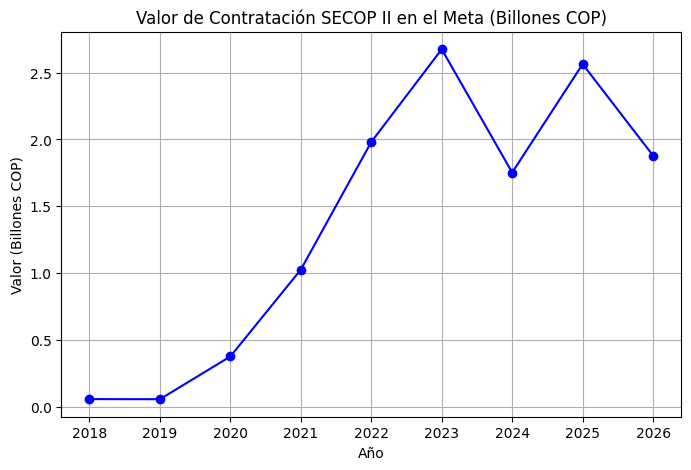

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(secop['anio'], secop['valor_billones'], marker='o', linestyle='-', color='b')
plt.title('Valor de Contratación SECOP II en el Meta (Billones COP)')
plt.xlabel('Año')
plt.ylabel('Valor (Billones COP)')
plt.grid(True)
plt.show()

In [9]:
secop.shape

(9, 4)

## 7. TRM histórica (Superfinanciera) · `32sa-8pi3`

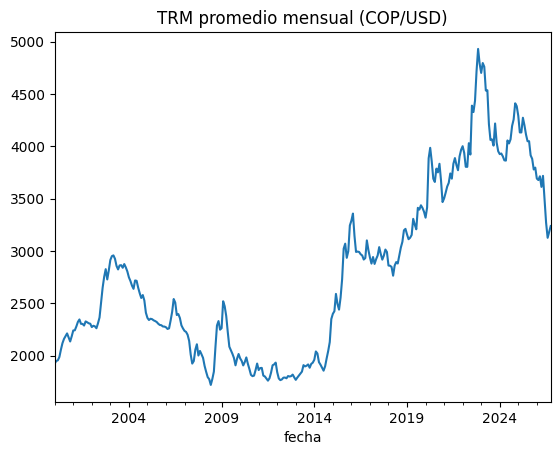

In [10]:
trm = socrata("32sa-8pi3", where="vigenciadesde >= '2000-01-01T00:00:00'", order="vigenciadesde")
trm["fecha"] = pd.to_datetime(trm["vigenciadesde"])
trm["valor"] = pd.to_numeric(trm["valor"])
trm.set_index("fecha")["valor"].resample("ME").mean().plot(title="TRM promedio mensual (COP/USD)");

## 8. Precipitación de estaciones IDEAM · `s54a-sgyg`

Es una tabla enorme: filtra siempre por municipio y rango de fechas.

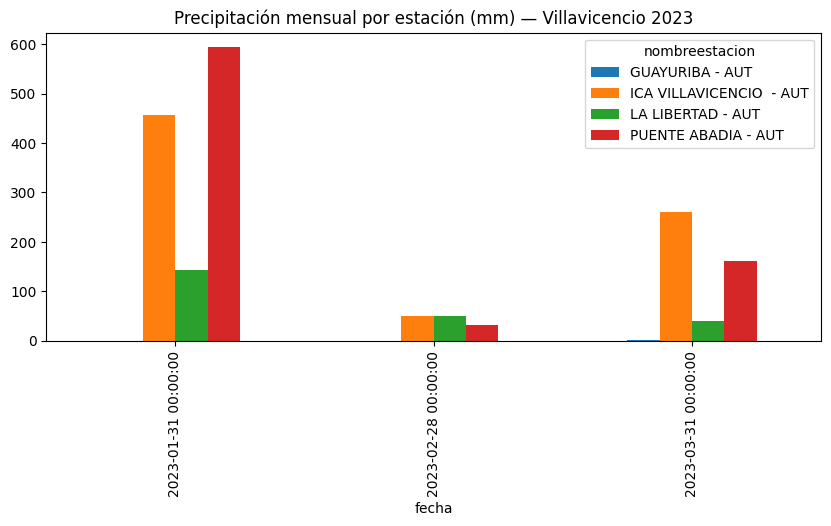

In [12]:
ppt = socrata("s54a-sgyg",
    select="codigoestacion, nombreestacion, fechaobservacion, valorobservado, latitud, longitud",
    where=("upper(municipio)='VILLAVICENCIO' "
           "AND fechaobservacion between '2023-01-01T00:00:00' and '2023-12-31T23:59:59'"))
ppt["fecha"] = pd.to_datetime(ppt["fechaobservacion"])
ppt["mm"] = pd.to_numeric(ppt["valorobservado"], errors="coerce")

ppt_mensual = (ppt.set_index("fecha")
                  .groupby("nombreestacion")["mm"]
                  .resample("ME").sum()
                  .unstack(0))
ppt_mensual.plot(kind="bar", figsize=(10, 4), title="Precipitación mensual por estación (mm) — Villavicencio 2023");

## 9. Temperatura del aire de estaciones IDEAM · `sbwg-7ju4`

In [ ]:
temp = socrata("sbwg-7ju4",
    select="nombreestacion, fechaobservacion, valorobservado",
    where=("upper(departamento)='META' "
           "AND fechaobservacion between '2024-01-01T00:00:00' and '2024-03-31T23:59:59'"))
temp["fecha"] = pd.to_datetime(temp["fechaobservacion"])
temp["t"] = pd.to_numeric(temp["valorobservado"], errors="coerce")
temp.set_index("fecha").groupby("nombreestacion")["t"].resample("D").mean().unstack(0).plot(
    figsize=(10, 4), legend=False, title="Temperatura media diaria por estación (°C) — Meta");

## 10. Banco Mundial (`wbgapi`) — indicadores país desde 1990

Para buscar códigos: `wb.series.info(q="poverty")`.

In [13]:
import wbgapi as wb

indicadores = {
    "NY.GDP.PCAP.KD": "pib_pc_usd_const",
    "SP.POP.TOTL":    "poblacion",
    "SI.POV.GINI":    "gini",
    "SL.UEM.TOTL.ZS": "desempleo_pct",
    "AG.LND.FRST.ZS": "bosque_pct_tierra",
}
wbdf = wb.data.DataFrame(list(indicadores), "COL", time=range(1990, 2025), numericTimeKeys=True)
wbdf = wbdf.T.rename(columns=indicadores)
wbdf.index.name = "anio"
wbdf.tail()

series,bosque_pct_tierra,pib_pc_usd_const,gini,desempleo_pct,poblacion
anio,,,,,
2020,54.189527,5891.955232,54.4,15.983,50629997.0
2021,54.069401,6457.169218,55.1,13.898,51188173.0
2022,53.949265,6856.725905,54.8,10.541,51737944.0
2023,53.829139,6837.373921,54.6,9.591,52321152.0
2024,53.709004,6865.312839,54.4,9.619,52886363.0


In [14]:
wbdf.shape

(35, 5)

## 11. NASA POWER — clima mensual por coordenada desde 1981 (sin clave)

`PRECTOTCORR` = precipitación (mm/día), `T2M` = temperatura a 2 m (°C).

In [ ]:
lat, lon = 4.142, -73.627          # Villavicencio
url = "https://power.larc.nasa.gov/api/temporal/monthly/point"
p = {"parameters": "PRECTOTCORR,T2M", "community": "AG",
     "latitude": lat, "longitude": lon, "start": 1985, "end": 2024, "format": "JSON"}
js = requests.get(url, params=p, timeout=120).json()["properties"]["parameter"]

power = pd.DataFrame(js)
power = power[~power.index.str.endswith("13")]          # quita el valor anual (mes 13)
power.index = pd.to_datetime(power.index, format="%Y%m")
power = power.replace(-999, pd.NA)
power["T2M"].plot(title="Temperatura media mensual (°C) — NASA POWER");

## 13. Biodiversidad — GBIF (incluye los datos que publica SiB Colombia)

Primero el conteo de registros por año (facetas) y luego una muestra de registros.

In [ ]:
gbif = "https://api.gbif.org/v1/occurrence/search"

# Conteo de registros por año en el Meta
r = requests.get(gbif, params={"country": "CO", "stateProvince": "Meta", "limit": 0,
                               "facet": "year", "facetLimit": 200}, timeout=60).json()
por_anio = pd.DataFrame(r["facets"][0]["counts"]).rename(columns={"name": "anio", "count": "registros"})
por_anio["anio"] = por_anio["anio"].astype(int)
por_anio.sort_values("anio").set_index("anio").loc[1990:].plot(kind="bar", figsize=(10, 3), legend=False,
                                                               title="Registros de biodiversidad en GBIF — Meta");

# Muestra de registros (aves), paginando de 300 en 300
filas = []
for offset in range(0, 900, 300):
    res = requests.get(gbif, params={"country": "CO", "stateProvince": "Meta", "classKey": 212,
                                     "hasCoordinate": "true", "limit": 300, "offset": offset},
                       timeout=60).json()["results"]
    filas += res
aves = pd.DataFrame(filas)[["species", "eventDate", "decimalLatitude", "decimalLongitude", "county"]]
aves.head()

## 14. Our World in Data — series largas país (ej. emisiones de CO₂ per cápita)

In [ ]:
owid = pd.read_csv("https://ourworldindata.org/grapher/co2-emissions-per-capita.csv",
                   storage_options={"User-Agent": "Mozilla/5.0"})
co2_col = owid[owid["Code"] == "COL"].set_index("Year").iloc[:, -1]
co2_col.loc[1950:].plot(title="Emisiones de CO₂ per cápita (t) — Colombia");

## 15. (Opcional) Google Earth Engine — precipitación CHIRPS por municipio

Requiere cuenta de Earth Engine y un proyecto de Google Cloud. Calcula la lluvia anual promedio de cada municipio del Meta.

In [ ]:
import ee
ee.Authenticate()                       # solo la primera vez
ee.Initialize(project="TU-PROYECTO-GCP")

municipios = (ee.FeatureCollection("FAO/GAUL/2015/level2")
                .filter(ee.Filter.eq("ADM0_NAME", "Colombia"))
                .filter(ee.Filter.eq("ADM1_NAME", "Meta")))

def lluvia_anual(anio):
    img = (ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
             .filterDate(f"{anio}-01-01", f"{anio + 1}-01-01").sum())
    fc = img.reduceRegions(collection=municipios, reducer=ee.Reducer.mean(), scale=5566)
    return pd.DataFrame([{"municipio": f["properties"]["ADM2_NAME"], "anio": anio,
                          "ppt_mm": f["properties"].get("mean")}
                         for f in fc.getInfo()["features"]])

chirps = pd.concat([lluvia_anual(a) for a in range(2015, 2025)], ignore_index=True)
chirps.pivot(index="anio", columns="municipio", values="ppt_mm").round(0).head()

## 16. Unir todo en un panel municipio–año

Cruce por código DIVIPOLA y año, con los nombres oficiales del DANE.

In [15]:
panel = (eva_anual[["cod_mpio", "anio", "produccion_t"]]
         .merge(edu[["cod_mpio", "anio", "cobertura_neta", "desercion"]], on=["cod_mpio", "anio"], how="outer")
         .merge(saber.groupby(["cod_mpio", "anio"], as_index=False)["prom_global"].mean(),
                on=["cod_mpio", "anio"], how="outer")
         .merge(divipola[["cod_mpio", "nom_mpio", "dpto"]], on="cod_mpio", how="left")
         .sort_values(["cod_mpio", "anio"]))

panel.to_csv("panel_municipal_meta.csv", index=False, encoding="utf-8-sig")
print(panel.shape)
panel.head(10)

NameError: name 'saber' is not defined